# Noisy-LJ latent-edge comparison

Both 2D AEs see four training trajectories and the same number of frame updates. One sees four noisy-LJ networks; the other sees one network from each of four sources. Both latent propagators then see the same 60 noisy-LJ trajectories. Added edges on held-out graphs use only frame 0; future frames and p-ratio are not used.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
HERE=Path.cwd().resolve()
ROOT=HERE.parents[1] if HERE.parent.name=='notebooks' else HERE
sys.path.insert(0,str(ROOT/'src'))
from lss.plotting import apply_editorial_style, PAPER_COLORS, style_axes
apply_editorial_style('light')
RESULTS=ROOT/'notebooks/results/lj_matched_scope'
summary=pd.read_csv(RESULTS/'postfit_seed_summary.csv')
per_network=pd.read_csv(RESULTS/'postfit_per_network.csv')
nodes=pd.read_csv(RESULTS/'visualization_nodes.csv')
edges=pd.read_csv(RESULTS/'visualization_edges.csv')
latent_scores=pd.read_csv(RESULTS/'validation_latent_edges.csv')
display(summary.round(4))

,arm,frame,postfit_p_ratio_r2_mean,postfit_p_ratio_r2_sd,coordinate_mse_mean,coordinate_mse_sd,p_ratio_valid,p_ratio_total
0,base,10,0.9068,0.0089,0.0000,0.0,60,60
1,base,20,0.7974,0.0201,0.0000,0.0,60,60
2,base,30,0.7321,0.0171,0.0000,0.0,60,60
3,base,40,0.6930,0.0245,0.0000,0.0,60,60
4,base,50,0.6523,0.0527,0.0000,0.0,60,60
5,base,60,0.6008,0.0885,0.0001,0.0,60,60
6,base,70,0.5466,0.1228,0.0001,0.0,60,60
7,base,80,0.4942,0.1530,0.0001,0.0,60,60
8,base,90,0.4446,0.1776,0.0002,0.0,60,60
9,base,100,0.3974,0.1962,0.0002,0.0,60,60


## Rollout response

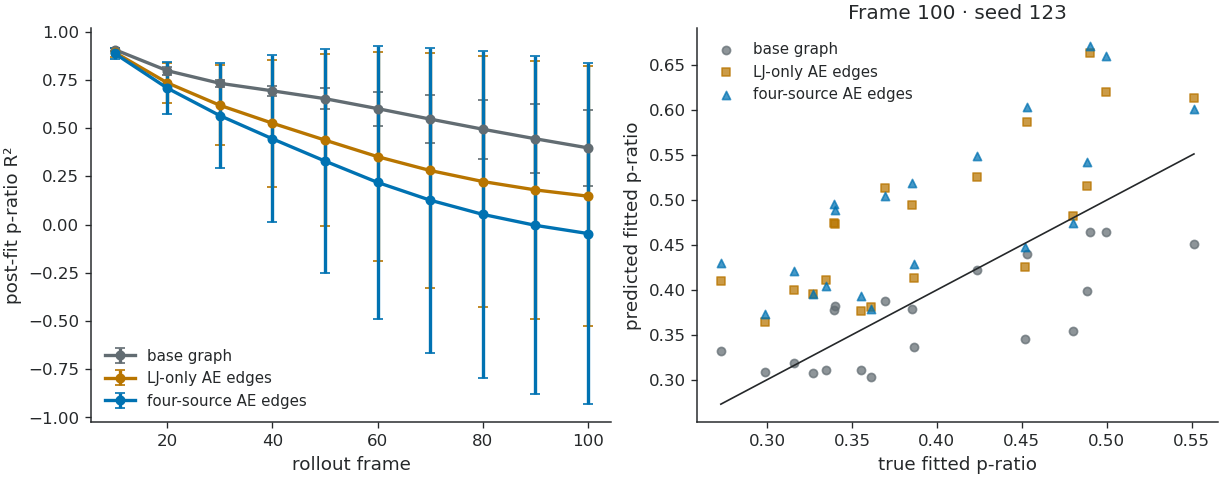

In [2]:
labels={'base':'base graph','ljonly4_latent':'LJ-only AE edges','shared4_latent':'four-source AE edges'}
colors={'base':PAPER_COLORS['slate'],'ljonly4_latent':PAPER_COLORS['orange'],'shared4_latent':PAPER_COLORS['blue']}
fig,axes=plt.subplots(1,2,figsize=(10.2,4),constrained_layout=True)
for arm,g in summary.groupby('arm'):
    axes[0].errorbar(g.frame,g.postfit_p_ratio_r2_mean,yerr=g.postfit_p_ratio_r2_sd,
                     marker='o',capsize=3,label=labels[arm],color=colors[arm])
style_axes(axes[0],xlabel='rollout frame',ylabel='post-fit p-ratio R²',legend=True)
frame=100
for arm,marker in [('base','o'),('ljonly4_latent','s'),('shared4_latent','^')]:
    g=per_network.query('frame==@frame and arm==@arm and seed==123')
    axes[1].scatter(g.true_p_ratio,g.pred_p_ratio,s=24,alpha=.72,marker=marker,
                    color=colors[arm],label=labels[arm])
limits=np.array([per_network.query('frame==@frame').true_p_ratio.min(),per_network.query('frame==@frame').true_p_ratio.max()])
axes[1].plot(limits,limits,color=PAPER_COLORS['ink'],lw=1)
style_axes(axes[1],xlabel='true fitted p-ratio',ylabel='predicted fitted p-ratio',legend=True)
axes[1].set_title('Frame 100 · seed 123')
plt.show()

## Added edges on an unseen graph

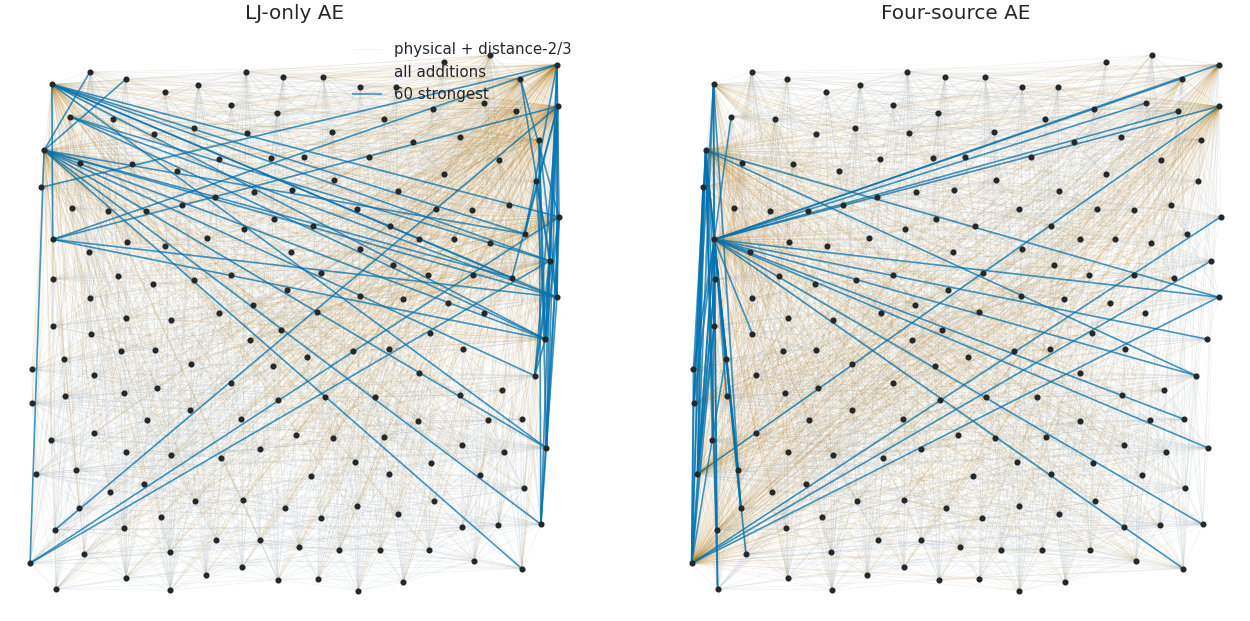

scope
ljonly4    899
shared4    901
Name: added edges on shown unseen graph, dtype: int64

In [3]:
fig,axes=plt.subplots(1,2,figsize=(11,5.2),constrained_layout=True)
for ax,scope in zip(axes,['ljonly4','shared4']):
    scope_nodes=nodes.query('scope==@scope')
    position=scope_nodes.set_index('node')[['x','y']]
    physical=edges.query("scope==@scope and edge_type=='physical'")
    added=edges.query("scope==@scope and edge_type=='latent'").merge(
        latent_scores.query('scope==@scope and seed==123')[['original_index','source_node','target_node','influence_score']],
        on=['original_index','source_node','target_node'],how='left')
    top=added.nlargest(min(60,len(added)),'influence_score')
    def segments(frame):
        return [[position.loc[int(row.source_node)].to_numpy(),position.loc[int(row.target_node)].to_numpy()]
                for row in frame.itertuples()]
    ax.add_collection(LineCollection(segments(physical),colors=PAPER_COLORS['light'],linewidths=.35,alpha=.28,label='physical + distance-2/3'))
    ax.add_collection(LineCollection(segments(added),colors=PAPER_COLORS['orange'],linewidths=.45,alpha=.10,label='all additions'))
    ax.add_collection(LineCollection(segments(top),colors=PAPER_COLORS['blue'],linewidths=1.0,alpha=.72,label='60 strongest'))
    ax.scatter(scope_nodes.x,scope_nodes.y,s=7,color=PAPER_COLORS['ink'],zorder=3)
    ax.set_aspect('equal'); ax.autoscale(); ax.axis('off')
    ax.set_title('LJ-only AE' if scope=='ljonly4' else 'Four-source AE')
axes[0].legend(frameon=False,loc='upper right')
plt.show()
display(edges.query("edge_type=='latent'").groupby('scope').size().rename('added edges on shown unseen graph'))